# Univariate data - Plots

This tutorial covers the built-in visuals of the `Univar` object: the standard view, the available layouts, the options for the data panel, fine-tuning and saving figures.

```{seealso}
Check out the {doc}`Univariate data - Basics <univar_01>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
from pathlib import Path
import numpy as np

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.datasets.analyst import Univar

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/univariate")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\univariate


## Sample data

Lets make a skewed sample, like daily discharge: most values are low, with a few high ones. Set the variable name and units **before** setting the data, so they are used as labels. The `.set_array()` method takes a `numpy` array directly:

In [2]:
rng = np.random.default_rng(seed=1)  # ensure reproducibility
v = rng.gamma(shape=2, scale=10, size=500)

unv = Univar(name="Discharge", alias="Q")
unv.varname = "Discharge"
unv.units = "m3/s"
unv.set_array(array=v)

## Standard visualization

Get the standard visual using the `.view()` method. The `full` layout shows the data points (in their original order), the histogram, the CDF (as exceedance probability) and a table of basic statistics:

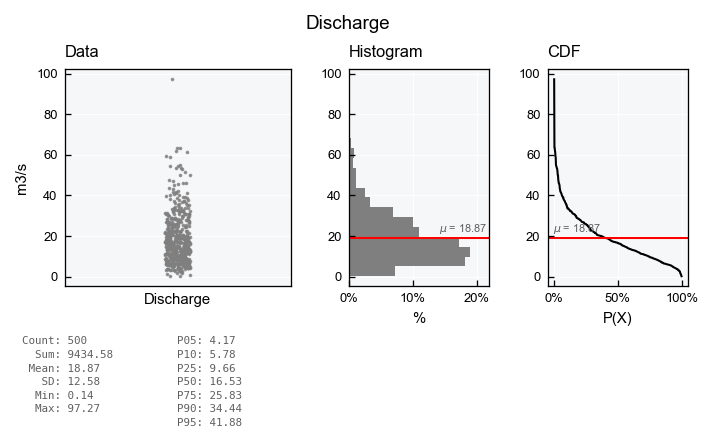

In [3]:
unv.view()

## Layouts

List available layout keys:

In [4]:
print(unv.layouts.keys())

dict_keys(['full', 'mini', 'simple', 'simple-shallow', 'qq', 'default'])


The `mini` layout drops the statistics table:

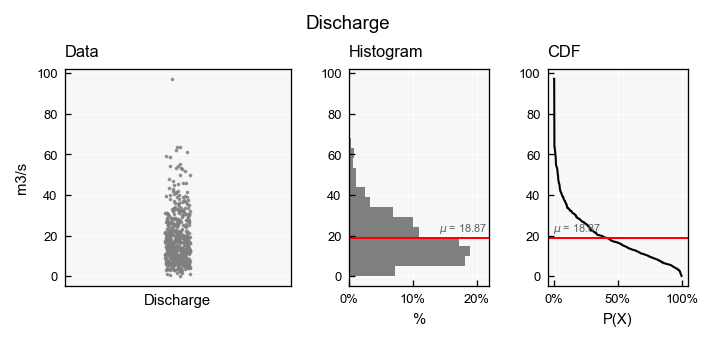

In [5]:
unv.view_specs["layout"] = "mini"
unv.view()

The `simple` layouts show the data panel only:

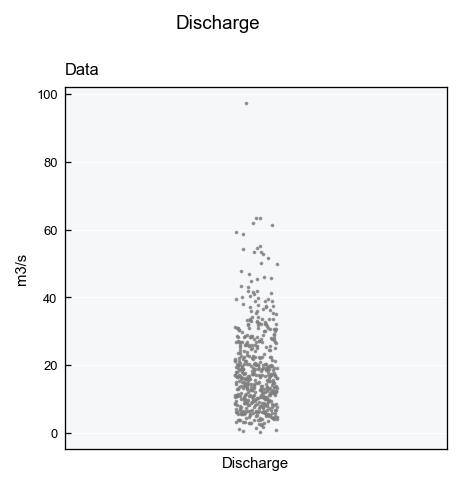

In [6]:
unv.view_specs["layout"] = "simple"
unv.view()

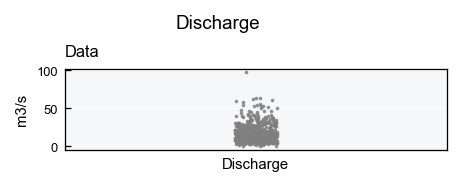

In [7]:
unv.view_specs["layout"] = "simple-shallow"
unv.view()

The `qq` layout is a Q-Q plot, which compares the data with a normal distribution. Points on the line follow the normal distribution of same mean and standard deviation. This skewed sample bends away from the line, mainly at the high values:

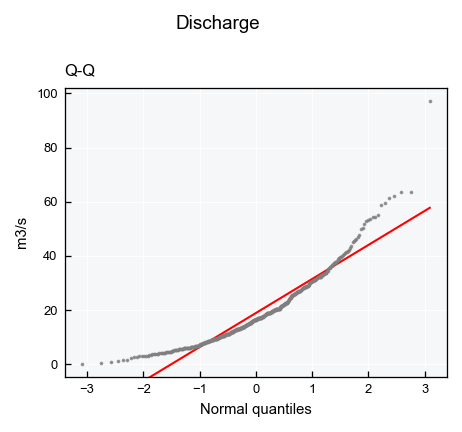

In [ ]:
unv.view_specs["layout"] = "qq"
unv.view()

## Data panel: scatter or boxplot

The data panel shows a scatter of the data points by default. Set `view_specs["data_plot"]` to `"boxplot"` for a boxplot instead. The box spans the first to the third quartile, with the median in black. Whiskers reach 1.5 times the interquartile range, and values beyond them are drawn as dots:

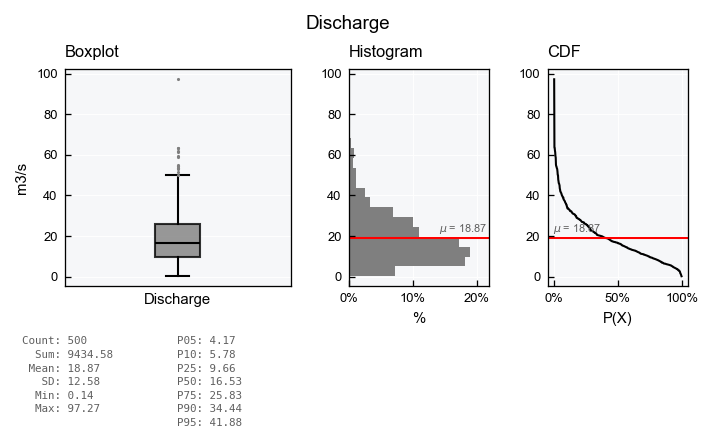

In [8]:
unv.view_specs["layout"] = "full"
unv.view_specs["data_plot"] = "boxplot"
unv.view()

Hide the outlier dots with `box_showfliers`, and add the mean line with `plot_mean_data`. For skewed data, the mean sits above the median, pulled up by the high values:

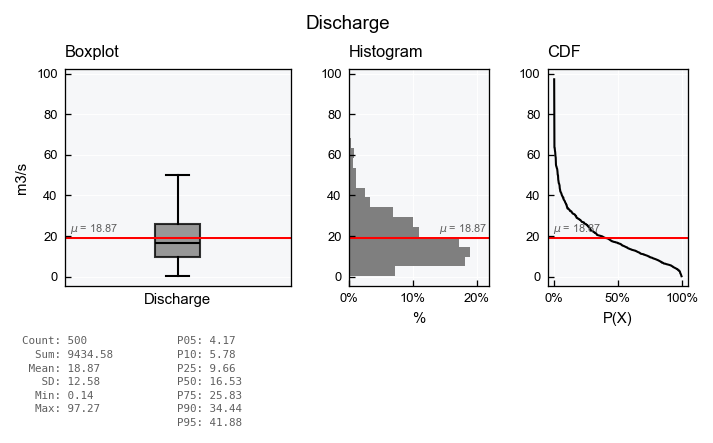

In [9]:
unv.view_specs["box_showfliers"] = False
unv.view_specs["plot_mean_data"] = True
unv.view()

## Colorized scatter

Back to the scatter, the data points can be colored by classes of value. The `scheme_cmap` key sets how classes are defined: `equal` for classes of equal width, or `quantiles` for classes with the same number of values. The `n_classes_cmap` key sets how many classes, five by default:

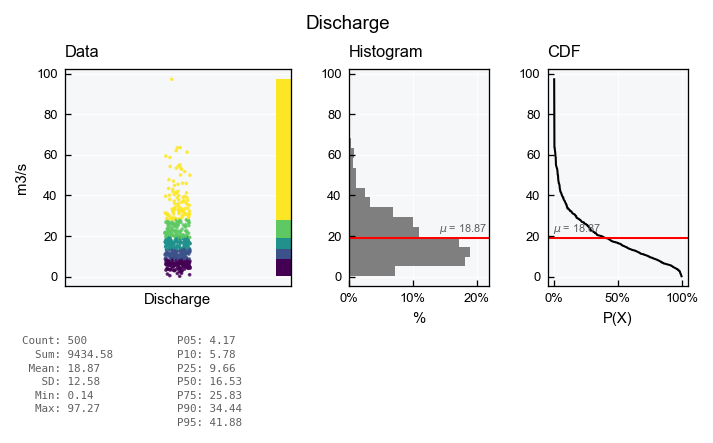

In [10]:
unv.view_specs["data_plot"] = "scatter"
unv.view_specs["plot_mean_data"] = False
unv.view_specs["colorize_scatter"] = True
unv.view_specs["scheme_cmap"] = "quantiles"
unv.view_specs["cmap"] = "viridis"
unv.view()

## Fine-tuning visuals

Use the `.view_specs` keys for fine tuning the visual. Example of some possibilities:

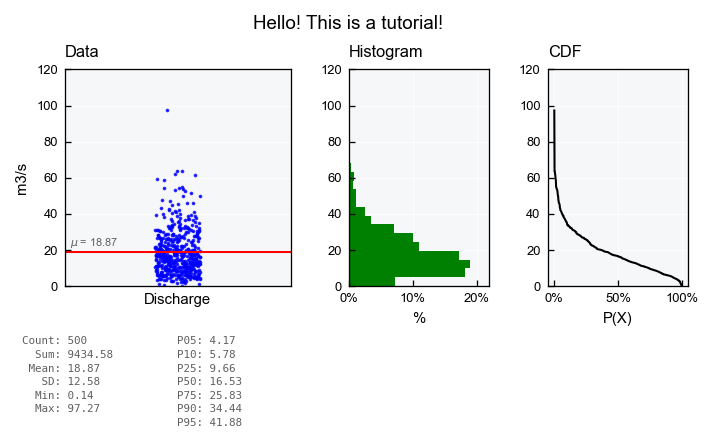

In [11]:
unv.view_specs["colorize_scatter"] = False
# Y axis range
unv.view_specs["range"] = [0, 120]
# Scatter
unv.view_specs["scatter_factor"] = 2  # occupy more space
# Color
unv.view_specs["color"] = "blue"
unv.view_specs["color_hist"] = "green"
# Decorations
unv.view_specs["plot_mean"] = False
unv.view_specs["plot_mean_data"] = True
unv.view_specs["title"] = "Hello! This is a tutorial!"
# call view again
unv.view()

Check out all keys available in `.view_specs`:

In [12]:
print(list(unv.view_specs.keys()))

['style', 'gs_wspace', 'gs_hspace', 'gs_left', 'gs_right', 'gs_bottom', 'gs_top', 'folder', 'filename', 'fig_format', 'dpi', 'title', 'xvar', 'yvar', 'xlabel', 'ylabel', 'color', 'xmin', 'xmax', 'ymin', 'ymax', 'layout', 'data_plot', 'subtitle_data', 'subtitle_box', 'subtitle_hist', 'subtitle_cdf', 'subtitle_qq', 'yvar_field', 'xlabel_cdf', 'xlabel_qq', 'data_label', 'data_legend', 'color_hist', 'color_cdf', 'color_mean', 'color_mean_text', 'scheme_cmap', 'n_classes_cmap', 'cmap', 'alpha', 'alpha_hist', 'alpha_cdf', 'range', 'range_x', 'plot_mean', 'plot_mean_data', 'linestyle_mean', 'pad_mean', 'plot_mean_label', 'hist_density', 'bins', 'bins_density', 'ax_data', 'ax_hist', 'ax_cdf', 'x_stats', 'x_stats_sep', 'y_stats', 'zorder_data', 'zorder_histh', 'zorder_cdf', 'scatter_factor', 'colorize_scatter', 'box_width', 'box_showfliers']


## Saving figures

Set the output folder, file name, format and resolution in `.view_specs`, and call `.view(show=False)` to save the figure instead of showing it:

In [13]:
unv.view_specs["folder"] = str(OUTPUT_DIR)
unv.view_specs["filename"] = "discharge"
unv.view_specs["fig_format"] = "png"
unv.view_specs["dpi"] = 300
unv.view(show=False)

print(list(OUTPUT_DIR.glob("discharge.*")))

[WindowsPath('outputs/univariate/discharge.png')]


To further customize a figure with `matplotlib`, get the figure object itself with `.view(return_fig=True)`.

## Recap

- `.view()` draws the standard visual; `view_specs["layout"]` switches between `full`, `mini`, `simple`, `simple-shallow` and `qq`.
- `view_specs["data_plot"]` sets the data panel as a `scatter` or a `boxplot`.
- All other options, including saving, are keys in `.view_specs`.